# Event Studies and Difference-in-Differences
### BU DX702 — Experimental Design and Causality

**Recurring question:** does GenAI help learning? Weeks 1–3 asked this about an
**individual student's** decision to use GenAI. This week the treatment changes: we're
now estimating the effect of a **school offering a GenAI tutoring program** — a school-level
policy, not a student-level choice. Same spirit, different treatment variable and a new
problem: policies start on a specific date, and other things can start on that date too.

All data are simulated for teaching. A known simulated effect is a benchmark for checking our
methods, not an empirical claim about GenAI.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

COLOR_EAST = "#D65F5F"
COLOR_WEST = "#4878CF"
COLOR_BAD = "#6ACC65"
COLOR_TRUTH = "grey"

# --- Simulation truth: instructor-only. The analyst never sees these. ---
N_WEEKS = 24
T0 = 8            # rollout week
A0 = 75.0         # baseline average quiz score
B_TREND = 0.3     # shared pre-existing weekly trend (both schools)
S_SHOCK = 3.0     # shared level shock at week 8 (district quiz recalibration) -- both schools
A_EFFECT = 1.5    # true program effect -- Eastfield only
SIGMA = 1.0       # noise sd on a weekly average score
SEED = 132

weeks = np.arange(1, N_WEEKS + 1)


def simulate_school(effect, seed_offset):
    """One school's weekly average quiz score: shared trend + shared week-8 shock + its own
    program effect (if any). `effect` is the school's true program effect; 0 for a school
    that never adopted the program."""
    rng = np.random.default_rng(1000 * seed_offset + SEED)
    r = weeks - T0
    P = (weeks >= T0).astype(int)
    y = A0 + B_TREND * r + S_SHOCK * P + effect * P + rng.normal(0, SIGMA, N_WEEKS)
    return pd.DataFrame({"week": weeks, "r": r, "P": P, "Y": y})


df_east = simulate_school(A_EFFECT, seed_offset=1)
df_west = simulate_school(0.0, seed_offset=2)

### What the analyst can and cannot see

| Symbol | Meaning | Visible to analyst? |
|--------|---------|---------------------|
| $S = 3.0$ | Shared week-8 shock (quiz recalibration) | **No** |
| $A = 1.5$ | True program effect, Eastfield only | **No** |
| $b = 0.3$ | True shared weekly trend | **No** |
| `week`, `Y` | Weekly average quiz score | Yes |
| `P` | Whether the week is at/after rollout | Yes |

The analyst sees a school's weekly average score and the rollout date — nothing else. Every
number an analyst reports below is computed only from what's in this table.

---
## 1. Eastfield High rolls out a GenAI tutoring program

Eastfield introduces a GenAI tutoring program at week 8. Here's the weekly average quiz score.

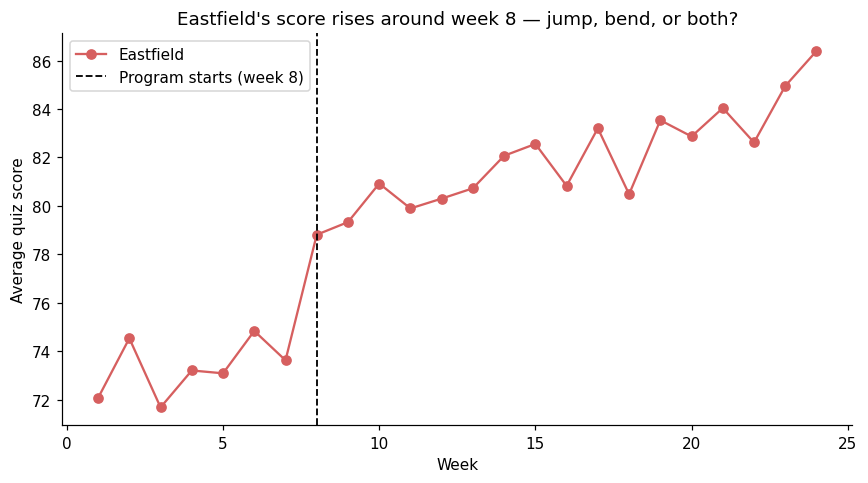

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_east["week"], df_east["Y"], "o-", color=COLOR_EAST, label="Eastfield")
ax.axvline(T0, color="black", ls="--", lw=1.2, label="Program starts (week 8)")
ax.set_xlabel("Week")
ax.set_ylabel("Average quiz score")
ax.set_title("Eastfield's score rises around week 8 — jump, bend, or both?")
ax.legend()
plt.tight_layout()
plt.show()

**Discussion 1.** From the picture alone: does this look like a one-time jump, a change in
slope, or both? What would you need to check to tell them apart?

<details><summary>Expand</summary>

A jump moves the level without changing the future trend; a slope change bends the line but
doesn't have to move it instantly. Both show up in the same picture — telling them apart
needs a regression that lets each happen separately, which is exactly what the polls this
session built toward.
</details>

### Assembling the model

The polls already gave you the pieces: a trend term, a post-program indicator, and an
interaction that lets the slope bend. Put together, centered at the rollout week:

$$Y = a + br + cP + d(rP) + \epsilon$$

- $r = \text{week} - 8$ (centered at rollout)
- $P = 1$ from week 8 onward, $0$ before
- $b$: the pre-existing weekly trend
- $c$: the level jump at week 8
- $d$: the change in slope after week 8

This extends the poll's model, which only had $r$ and $rP$ — adding $cP$ is what lets the
model represent a jump at all, separately from a bend.

In [3]:
# Note: `"Y ~ r + P + r:P"` is shorthand — statsmodels builds the actual design matrix
# (intercept, r, P, r*P) and fits OLS on it. Try building that matrix yourself and fitting it
# with `sm.OLS(y, X).fit()` — you should get exactly the same coefficients.
m_event = smf.ols("Y ~ r + P + r:P", data=df_east).fit()
print(m_event.summary2().tables[1].round(3))

            Coef.  Std.Err.       t  P>|t|  [0.025  0.975]
Intercept  74.244     0.888  83.599  0.000  72.391  76.096
r           0.239     0.199   1.201  0.244  -0.176   0.653
P           4.845     1.013   4.781  0.000   2.731   6.959
r:P         0.122     0.205   0.595  0.559  -0.306   0.550


**Reading the coefficients:**

In [4]:
print(f"b (weekly trend)      : {m_event.params['r']:+.2f}   [true value: {B_TREND:+.2f}]")
print(f"c (jump at week 8)    : {m_event.params['P']:+.2f}   [true S+A combined: {S_SHOCK + A_EFFECT:+.2f}]")
print(f"d (slope change)      : {m_event.params['r:P']:+.2f}   "
      f"95% CI [{m_event.conf_int().loc['r:P'][0]:+.2f}, {m_event.conf_int().loc['r:P'][1]:+.2f}]")

b (weekly trend)      : +0.24   [true value: +0.30]
c (jump at week 8)    : +4.84   [true S+A combined: +4.50]
d (slope change)      : +0.12   95% CI [-0.31, +0.55]


| Potential conclusion | What the analysis actually supports |
|---|---|
| *"$c$'s interval doesn't include zero — is the level jump real?"* | Yes — that part is solid. The jump is precisely estimated, not noise. |
| *"$d$'s interval includes zero — can we conclude there's no change in slope, only a jump?"* | Not quite. An insignificant estimate rules out a *large* bend, not *any* bend — "interval includes zero" isn't proof the true slope change is zero. (It happens to be exactly zero here, but that's revealed only after Section 2's reveal — not something the analyst can claim yet.) |
| *"The jump is large and significant — does that mean the GenAI program caused it?"* | Not from this data alone. Week 8 is also when the district recalibrated quiz difficulty. Eastfield's series alone can't separate the program's effect from the recalibration's effect — that's why one school isn't enough. |

---
## 2. Difference-in-differences: Westbrook as a comparison

Westbrook High is a comparable school. It did not adopt the GenAI program at week 8.

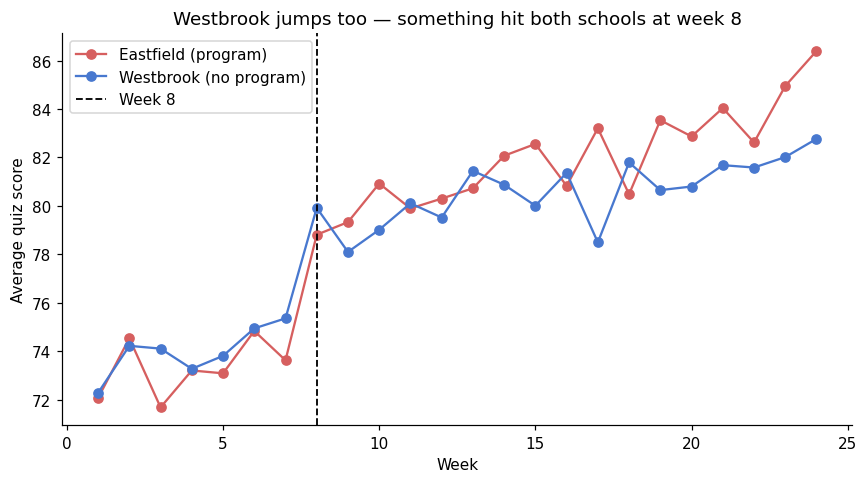

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_east["week"], df_east["Y"], "o-", color=COLOR_EAST, label="Eastfield (program)")
ax.plot(df_west["week"], df_west["Y"], "o-", color=COLOR_WEST, label="Westbrook (no program)")
ax.axvline(T0, color="black", ls="--", lw=1.2, label="Week 8")
ax.set_xlabel("Week")
ax.set_ylabel("Average quiz score")
ax.set_title("Westbrook jumps too — something hit both schools at week 8")
ax.legend()
plt.tight_layout()
plt.show()

**Discussion 2.** Westbrook jumps at week 8 too, despite never adopting the program. What does
that imply about Eastfield's jump?

<details><summary>Expand</summary>

Westbrook shows how Eastfield's score would have **changed** without the program — not what
its level would have been. A permanent difference in school quality is fine; it cancels out in
the subtraction. What has to be shared is the size of the *movement* from before to after.
</details>

### DiD by hand

In [6]:
east_before = df_east.loc[df_east.P == 0, "Y"].mean()
east_after = df_east.loc[df_east.P == 1, "Y"].mean()
west_before = df_west.loc[df_west.P == 0, "Y"].mean()
west_after = df_west.loc[df_west.P == 1, "Y"].mean()

pivot = pd.DataFrame(
    {"Before": [east_before, west_before], "After": [east_after, west_after]},
    index=["Eastfield", "Westbrook"],
).round(2)
print(pivot)

did_by_hand = (east_after - east_before) - (west_after - west_before)
print(f"\nDiD = (Eastfield after - before) - (Westbrook after - before) = {did_by_hand:+.3f}")

           Before  After
Eastfield   73.29  81.97
Westbrook   74.00  80.60

DiD = (Eastfield after - before) - (Westbrook after - before) = +2.084


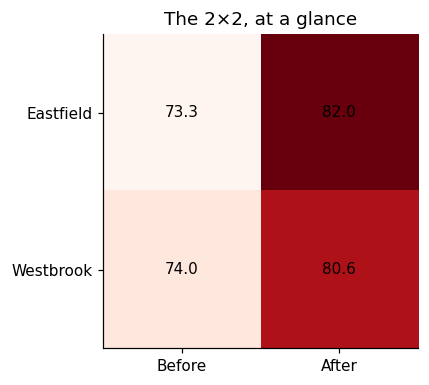

In [7]:
fig, ax = plt.subplots(figsize=(4, 3.6))
im = ax.imshow(pivot.values, cmap="Reds", aspect="auto")
ax.set_xticks([0, 1], labels=["Before", "After"])
ax.set_yticks([0, 1], labels=["Eastfield", "Westbrook"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{pivot.values[i, j]:.1f}", ha="center", va="center")
ax.set_title("The 2×2, at a glance")
plt.tight_layout()
plt.show()

### Connecting the by-hand number to a regression

In [8]:
panel = pd.concat(
    [df_east.assign(school="Eastfield", Treated=1),
     df_west.assign(school="Westbrook", Treated=0)],
    ignore_index=True,
)
panel["TreatedPost"] = panel["Treated"] * panel["P"]

m_naive = smf.ols("Y ~ Treated + P + TreatedPost", data=panel).fit()
print(m_naive.summary2().tables[1].round(3))
print(f"\nRegression interaction matches by-hand DiD: "
      f"{np.isclose(m_naive.params['TreatedPost'], did_by_hand)}")

              Coef.  Std.Err.        t  P>|t|  [0.025  0.975]
Intercept    73.997     0.598  123.733  0.000  72.792  75.202
Treated      -0.708     0.846   -0.837  0.407  -2.412   0.997
P             6.599     0.711    9.288  0.000   5.167   8.032
TreatedPost   2.084     1.005    2.074  0.044   0.059   4.110

Regression interaction matches by-hand DiD: True


$Y = a + b\,\text{Treated} + c\,\text{Post} + d(\text{Treated} \times \text{Post}) + \epsilon$ —
the coefficient on $\text{Treated}\times\text{Post}$ **is** the DiD estimate.
This is the point-estimate story, and it's correct as far as it goes — but it ignores that both
schools are still trending week to week, not sitting at two flat levels. Because the model
never includes `r`, it silently collapses each period down to a single average and treats
whatever's left as noise — except part of what's left is the trend itself. The interaction term
survives this untouched (the trend cancels in the double-difference, as we checked), but the
residual variance the standard error is computed from does not — it's inflated by real,
structured movement that got mislabeled as noise. Its standard error is not yet trustworthy —
see Section 3 — so don't lean on significance here.

### Derivation: where does this regression form come from? (optional)

It can look like `Treated + Post + Treated:Post` was picked out of thin air. It wasn't — it's
what's left after two specific assumptions strip down a much more general model.

**Start as general as possible: give each school its own full event-study equation**, and let
every term differ by group. Interact everything with a treated indicator $X = 0 \text{ or } 1$:

$$Y = a + a_X X + br + b_X(rX) + cP + c_X(XP) + d(rP) + d_X(rXP)$$

| Term | Meaning |
|---|---|
| $a$, $a_X$ | intercept; how much the treated school's intercept differs |
| $b$, $b_X$ | shared pre-trend; how much the treated school's pre-trend differs |
| $c$, $c_X$ | shared level shift at the event; how much the treated school's level shift differs |
| $d$, $d_X$ | shared slope change at the event; how much the treated school's slope change differs |

**Step 1 — no trend-shift mechanism.** We built the program as a constant boost, not a change in
growth rate (Section 1's "the estimated slope change is small" already pointed this way). That
assumption removes any slope-change term, shared or differential:

$$d = 0, \quad d_X = 0 \;\Rightarrow\; Y = a + a_X X + br + b_X(rX) + cP + c_X(XP)$$

**Step 2 — parallel trends.** Absent the program, the two schools would have moved the same way
— no differential *pre-existing* trend:

$$b_X = 0 \;\Rightarrow\; Y = a + a_X X + br + cP + c_X(XP)$$

Five terms left. **Step 3 — collapse to period averages.** Classic 2×2 DiD doesn't model the
*shape* of movement within a period at all — it only compares one number for "before" to one
number for "after." That means $r$ itself drops out too, leaving:

$$Y = a + a_X X + cP + c_X(XP)$$

— exactly `Y ~ Treated + P + Treated:Post`, the model fit above. This four-term model is the
**saturated** model for a 2 (school) × 2 (period) table: four free parameters for exactly four
group–period cells (Eastfield-before, Eastfield-after, Westbrook-before, Westbrook-after), no
more and no fewer. That's why its fitted coefficients reproduce the four cell means exactly, and
why $c_X$ — the coefficient on `Treated:Post` — comes out identical to the by-hand DiD number,
not merely close to it.

### The reveal — comparing like with like

Both numbers below are level jumps over the same post-program window, so comparing them is
fair:

In [9]:
naive_jump = m_event.params["P"]
did_estimate = m_naive.params["TreatedPost"]
print(f"Eastfield alone (Section 1's c)         : {naive_jump:+.2f}")
print(f"DiD-adjusted (program effect only)      : {did_estimate:+.2f}")
print(f"[for reference only — not analyst-visible] true program effect A = {A_EFFECT:+.2f}")

Eastfield alone (Section 1's c)         : +4.84
DiD-adjusted (program effect only)      : +2.08
[for reference only — not analyst-visible] true program effect A = +1.50


Eastfield's own jump was nearly 5 points. Once Westbrook's shared change is subtracted out,
the program's estimated effect drops to about 2 points — less than half. Most of what looked
like a GenAI win was the shared recalibration, not the program.

**Key takeaway:** a plausible, positive-looking single-school result mostly evaporates once you
have a real comparison.

**Optional — stability check.** Does the DiD-adjusted gap hold up over the weeks following
rollout, or fade?

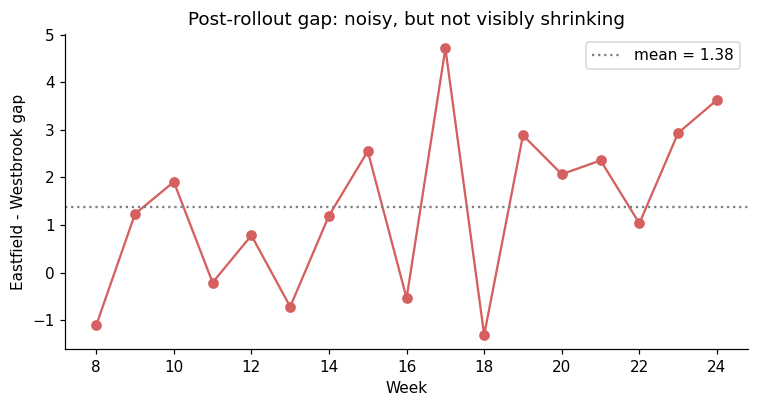

In [10]:
post = panel[panel.P == 1]
weekly_gap = (
    post[post.school == "Eastfield"].set_index("week")["Y"]
    - post[post.school == "Westbrook"].set_index("week")["Y"]
)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(weekly_gap.index, weekly_gap.values, "o-", color=COLOR_EAST)
ax.axhline(weekly_gap.mean(), color=COLOR_TRUTH, ls=":", label=f"mean = {weekly_gap.mean():.2f}")
ax.set_xlabel("Week"); ax.set_ylabel("Eastfield - Westbrook gap")
ax.set_title("Post-rollout gap: noisy, but not visibly shrinking")
ax.legend()
plt.tight_layout()
plt.show()

It's noisy week to week, as any 24-week series would be, but it isn't trending down. This
dataset intentionally contains no fading effect — this is the kind of check you'd run in
practice, since novelty/Hawthorne effects (people behave differently just because something is
new) are a real and common concern, not a dramatic reveal here.

**Discussion 3.** Both schools are visibly higher after week 8. Why not skip the "before"
period entirely and just compare `Eastfield_after − Westbrook_after`?

<details><summary>Expand</summary>

That comparison cancels the shared shock $S$ — it's baked into both averages equally. But it
does **not** cancel any *permanent* difference between the schools that existed all along
(different funding, different students, anything true both before and after week 8). The
double-difference cancels that too, because the permanent difference shows up in *both* of
Eastfield's own before/after numbers and is removed before the schools are ever compared to
each other. In this simulation the two schools happen to share the same baseline, so an
after-only comparison would look fine here — but that's a property of this dataset, not a
guarantee the method gives you.
</details>

In [11]:
# Illustrative only: give Eastfield a permanent, treatment-unrelated disadvantage and see how
# an after-only comparison reacts, versus the double-difference.
def simulate_with_gap(effect, permanent_gap, seed_offset):
    rng = np.random.default_rng(1000 * seed_offset + SEED)
    r = weeks - T0
    P = (weeks >= T0).astype(int)
    y = A0 + permanent_gap + B_TREND * r + S_SHOCK * P + effect * P + rng.normal(0, SIGMA, N_WEEKS)
    return pd.DataFrame({"week": weeks, "r": r, "P": P, "Y": y})


demo_east = simulate_with_gap(A_EFFECT, permanent_gap=-5.0, seed_offset=1)
demo_west = simulate_with_gap(0.0, permanent_gap=0.0, seed_offset=2)

after_only = demo_east.loc[demo_east.P == 1, "Y"].mean() - demo_west.loc[demo_west.P == 1, "Y"].mean()
did_demo = ((demo_east.loc[demo_east.P == 1, "Y"].mean() - demo_east.loc[demo_east.P == 0, "Y"].mean())
            - (demo_west.loc[demo_west.P == 1, "Y"].mean() - demo_west.loc[demo_west.P == 0, "Y"].mean()))

print(f"After-only (East_after - West_after) : {after_only:+.2f}   "
      f"(true A={A_EFFECT}, but a permanent -5 gap is baked in)")
print(f"DiD (double difference)              : {did_demo:+.2f}   "
      f"(unaffected by the permanent gap)")

After-only (East_after - West_after) : -3.62   (true A=1.5, but a permanent -5 gap is baked in)
DiD (double difference)              : +2.08   (unaffected by the permanent gap)


---
## 3. Assumptions and uncertainty

**What DiD actually assumes.** Not that the schools start at the same level — different
baselines are fine.

> The assumption DiD needs is that **without the program, the two schools would have changed
> similarly.** Similar pre-program trends are evidence *for* that assumption — they do not
> establish it. What would break the design is different **trajectories** going forward for
> reasons other than the program.

**Discussion 4.** Look back at the two-school plot. What in that picture makes Westbrook a
believable stand-in for what Eastfield would have done without the program?

<details><summary>Expand</summary>

The two schools track each other closely *before* week 8 — similar level, similar slope.
That's what makes it plausible that Westbrook's post-week-8 path is a reasonable stand-in for
Eastfield's counterfactual. It's evidence, not proof: nothing here rules out the two schools
diverging for unrelated reasons starting exactly at week 8.
</details>

### Why the naive regression's standard error isn't trustworthy yet

Both schools' scores carry the shared weekly trend $b$ straight through the
`Treated + Post + Treated×Post` model above — which never included a trend or time term at
all. That trend sits in the residuals as a systematic, non-random pattern:

In [12]:
corr_resid_week = np.corrcoef(m_naive.resid, panel["week"])[0, 1]
print(f"corr(naive residuals, week) = {corr_resid_week:+.3f}   "
      f"(nonzero -> the trend is leaking into what should be pure noise)")

corr(naive residuals, week) = +0.478   (nonzero -> the trend is leaking into what should be pure noise)


The fix is the same trend term Section 1 already used — just add `r` to the DiD regression:

In [13]:
m_with_r = smf.ols("Y ~ Treated + r + P + TreatedPost", data=panel).fit()

print(f"TreatedPost, naive (no r)  : coef={m_naive.params['TreatedPost']:+.3f}  SE={m_naive.bse['TreatedPost']:.3f}")
print(f"TreatedPost, with r        : coef={m_with_r.params['TreatedPost']:+.3f}  SE={m_with_r.bse['TreatedPost']:.3f}")
print(f"Point estimates match: {np.isclose(m_naive.params['TreatedPost'], m_with_r.params['TreatedPost'])}")

corr_resid_week_r = np.corrcoef(m_with_r.resid, panel["week"])[0, 1]
print(f"corr(residuals, week), with r included: {corr_resid_week_r:+.4f}   (was {corr_resid_week:+.3f})")

TreatedPost, naive (no r)  : coef=+2.084  SE=1.005
TreatedPost, with r        : coef=+2.084  SE=0.640
Point estimates match: True
corr(residuals, week), with r included: -0.0000   (was +0.478)


Adding `r` plugs the leak: the point estimate on `TreatedPost` doesn't move — confirming it was
never biased by the omitted trend — but its standard error shrinks, because the residuals no
longer carry a systematic pattern. The reported SE is now trustworthy, provided the remaining
errors really are independent and similarly sized across school-week observations — which is
what we built into the simulation. A real dataset would need to earn that assumption, not
assume it.

---
## 4. Recap and looking ahead

Westbrook worked as a comparison because we could point to its **trend**, not just its level.
What if the district hadn't handed us a school that easy to defend?

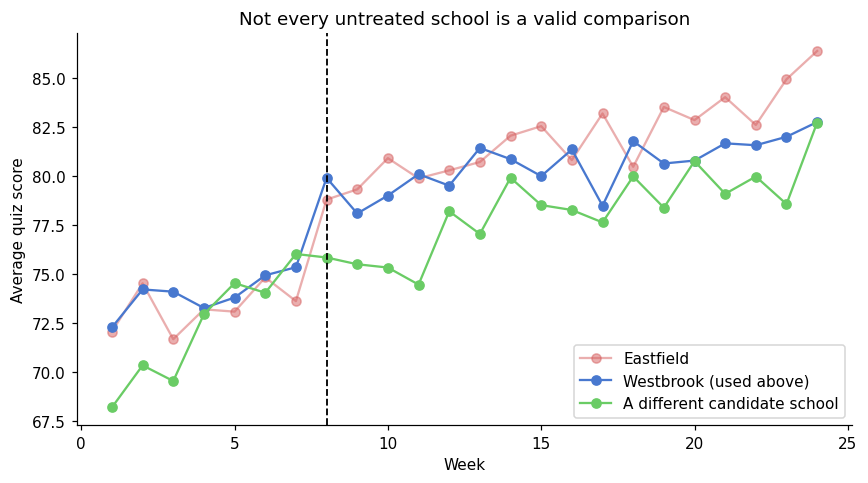

In [14]:
rng_bad = np.random.default_rng(9)
bad_pre_weeks = weeks[weeks < T0]
bad_pre = (A0 - 6 + 1.1 * (bad_pre_weeks - bad_pre_weeks.min())
           + rng_bad.normal(0, SIGMA, len(bad_pre_weeks)))
bad_post_weeks = weeks[weeks >= T0]
bad_post = ((A0 - 6 + 1.1 * (bad_pre_weeks.max() - bad_pre_weeks.min()))
            + B_TREND * (bad_post_weeks - T0) + rng_bad.normal(0, SIGMA, len(bad_post_weeks)))
df_bad = pd.DataFrame({"week": weeks, "Y": np.concatenate([bad_pre, bad_post])})

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_east["week"], df_east["Y"], "o-", color=COLOR_EAST, alpha=0.5, label="Eastfield")
ax.plot(df_west["week"], df_west["Y"], "o-", color=COLOR_WEST, label="Westbrook (used above)")
ax.plot(df_bad["week"], df_bad["Y"], "o-", color=COLOR_BAD, label="A different candidate school")
ax.axvline(T0, color="black", ls="--", lw=1.2)
ax.set_xlabel("Week"); ax.set_ylabel("Average quiz score")
ax.set_title("Not every untreated school is a valid comparison")
ax.legend()
plt.tight_layout()
plt.show()

The green school is untreated too, but its pre-week-8 trend is nothing like Eastfield's — it
was already climbing steeply on its own. Comparing Eastfield to *this* school would not be
defensible the way Westbrook was, even though both are "schools without the program." Different
starting **levels** are fine for DiD; a different untreated **trajectory** — for instance a
school recovering from an unusually bad prior stretch — is what actually breaks the design.

We can't always find a school we can defend the way we defended Westbrook. Next week:
regression discontinuity and instrumental variables give us other ways to justify a comparison
when parallel trends can't be argued directly.

## Takeaways

1. An interrupted time series reads a break in trend at a known time — a jump and a slope
   change are different claims, and a regression that includes both can tell them apart.
2. DiD's 2×2 table and its regression form are the same object — the interaction coefficient
   *is* the DiD estimate — and it isolates the program's effect only if the shared shock truly
   is shared, and only if there's no permanent difference between the groups left uncancelled.
3. The assumption DiD buys is "similar trends without treatment," not "similar levels," and
   it's supported by evidence, not proven by it.
4. When we can't defend a comparison school this way, the *reason* treatment was assigned
   becomes the thing to exploit instead — regression discontinuity and instrumental variables,
   next week.